# DSCI 552 — Homework 7
**Danmu Agudanmu****USC ID: 1414053340**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix,
                             roc_auc_score, roc_curve, silhouette_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

SEED = 42
DATA = "../Homework 7 Data/"
LABELS = ["Family", "Genus", "Species"]
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   # also for the joblib worker processes

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a) Load data and split

I drop `RecordID` (it only identifies the recording) and use a random 70% of the rows for training.

In [2]:
df = pd.read_csv(DATA + "Frogs_MFCCs.csv")
X = df.filter(like="MFCCs")
Y = df[LABELS]
classes = {lab: np.sort(Y[lab].unique()) for lab in LABELS}

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=SEED)
print("full data:", X.shape, " train:", X_train.shape, " test:", X_test.shape)
print({lab: len(classes[lab]) for lab in LABELS})

full data: (7195, 22)  train: (5036, 22)  test: (2159, 22)
{'Family': 4, 'Genus': 8, 'Species': 10}


In [3]:
print(f"all attributes lie in [{X.min().min():.2f}, {X.max().max():.2f}]")
print(f"standard deviations range from {X.std().min():.2f} to {X.std().max():.2f}")

all attributes lie in [-0.95, 1.00]
standard deviations range from 0.07 to 0.26


The attributes are already in $[-1, 1]$ (each row was divided by its largest absolute MFCC), as footnotes 2 and 4 say.

In [4]:
counts = pd.concat({lab: pd.DataFrame({"train": Y_train[lab].value_counts(),
                                       "test": Y_test[lab].value_counts()})
                    for lab in LABELS})
counts

train  test
Family  Leptodactylidae          3073  1347
        Hylidae                  1542   623
        Dendrobatidae             380   162
        Bufonidae                  41    27
Genus   Adenomera                2899  1251
        Ameerega                  380   162
        Dendropsophus             226    84
        Hypsiboas                1125   468
        Leptodactylus             174    96
        Osteocephalus              80    34
        Rhinella                   41    27
        Scinax                    111    37
Species AdenomeraAndre            452   220
        AdenomeraHylaedactylus   2447  1031
        Ameeregatrivittata        380   162
        HylaMinuta                226    84
        HypsiboasCinerascens      337   135
        HypsiboasCordobae         788   333
        LeptodactylusFuscus       174    96
        OsteocephalusOophagus      80    34
        Rhinellagranulosa          41    27
        ScinaxRuber               111    37

All three labels are imbalanced: *Leptodactylidae* has 61% of the syllables, while *Bufonidae* (= *Rhinella* = *Rhinellagranulosa*, the same 68 syllables) has less than 1%.

### (b) Binary relevance: one classifier per label

#### i. Exact match and Hamming score / loss

Let $Y_i = (y_{i1}, y_{i2}, y_{i3})$ be the true (family, genus, species) of syllable $i$, $\hat Y_i$ the prediction, $n$ the number of instances and $L = 3$.

- **Exact match ratio:** $\frac{1}{n}\sum_i I(\hat Y_i = Y_i)$, the fraction of syllables with all three labels correct.
- **Hamming distance:** $d_i = \sum_{j=1}^{L} I(\hat y_{ij} \ne y_{ij})$, the number of wrong labels of instance $i$.
- **Hamming loss:** $\frac{1}{nL}\sum_i d_i$, the fraction of wrong labels.
- **Hamming score:** $1 - \text{Hamming loss}$.

Sorower defines the Hamming loss over binary indicators. I treat family, genus and species as three multi-class labels instead, which only rescales the loss (by $2 \cdot 3/22$ for the 22 indicators). Some papers call the Jaccard accuracy $\frac{1}{n}\sum_i |Y_i \cap \hat Y_i| / |Y_i \cup \hat Y_i|$ the Hamming score; I use $1 - \text{Hamming loss}$ throughout.

In [5]:
def multilabel_scores(Y_true, Y_pred):
    wrong = np.asarray(Y_true) != np.asarray(Y_pred)
    d = wrong.sum(axis=1)                      # Hamming distance of each instance
    out = {f"acc {lab}": 1 - wrong[:, j].mean() for j, lab in enumerate(LABELS)}
    out["exact match"] = (d == 0).mean()
    out["Hamming loss"] = d.mean() / len(LABELS)
    out["Hamming score"] = 1 - d.mean() / len(LABELS)
    return out

scores, preds, dec = {}, {}, {}

def record(name, models):
    P = pd.DataFrame({lab: models[lab].predict(X_test) for lab in LABELS}, index=X_test.index)
    preds[name] = P
    dec[name] = {lab: models[lab].decision_function(X_test) for lab in LABELS}
    scores[name] = multilabel_scores(Y_test, P)
    return pd.DataFrame(scores[name], index=[name])

#### ii. Gaussian kernel SVM, one-vs-all

scikit-learn's kernel is $\exp(-\gamma \|x - x'\|^2)$, so a width $\sigma$ means $\gamma = 1/(2\sigma^2)$. I wrap `SVC` (one-vs-one by default) in `OneVsRestClassifier` to get one-vs-all classifiers.

**Choosing the ranges (footnote 1).** I fit the SVM on the full training set for very small and very large $C$ and $\sigma$. The table shows the lowest training accuracy over the three labels.

In [6]:
def gauss_svm(C=1.0, sigma=1.0, scale=False):
    svm = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=1 / (2 * sigma ** 2)))
    steps = [("scale", StandardScaler())] if scale else []
    return Pipeline(steps + [("svm", svm)])

def train_acc(lab, C, sigma, scale):
    model = gauss_svm(C, sigma, scale).fit(X_train, Y_train[lab])
    return model.score(X_train, Y_train[lab])

C_wide = 10.0 ** np.arange(-3, 6)
sigma_wide = [0.1, 0.5, 1, 2, 5, 10]
jobs = [(lab, C, s, sc) for sc in [False, True] for lab in LABELS for C in C_wide for s in sigma_wide]
acc = Parallel(n_jobs=-1)(delayed(train_acc)(*j) for j in jobs)

wide = pd.DataFrame(jobs, columns=["label", "C", "sigma", "scale"]).assign(train_acc=acc)
wide["features"] = wide["scale"].map({False: "raw", True: "standardized"})
wide.groupby(["features", "C", "sigma"]).train_acc.min().unstack("sigma").round(3)

sigma                     0.1    0.5    1.0    2.0    5.0    10.0
features     C                                                   
raw          0.001       0.576  0.576  0.546  0.535  0.534  0.536
             0.010       0.589  0.881  0.836  0.649  0.532  0.532
             0.100       0.737  0.966  0.914  0.870  0.663  0.560
             1.000       1.000  0.995  0.973  0.931  0.878  0.814
             10.000      1.000  1.000  0.993  0.971  0.930  0.897
             100.000     1.000  1.000  0.999  0.990  0.960  0.936
             1000.000    1.000  1.000  1.000  0.998  0.982  0.957
             10000.000   1.000  1.000  1.000  1.000  0.994  0.976
             100000.000  1.000  1.000  1.000  1.000  0.998  0.992
standardized 0.001       0.576  0.576  0.576  0.576  0.561  0.526
             0.010       0.576  0.576  0.650  0.873  0.849  0.787
             0.100       0.576  0.600  0.911  0.983  0.933  0.883
             1.000       1.000  1.000  1.000  0.999  0.982  0.945
             10.000      1.000  1.000  1.000  1.000  0.998  0.980
             100.000     1.000  1.000  1.000  1.000  1.000  0.995
             1000.000    1.000  1.000  1.000  1.000  1.000  1.000
             10000.000   1.000  1.000  1.000  1.000  1.000  1.000
             100000.000  1.000  1.000  1.000  1.000  1.000  1.000

Raw: $C \le 0.01$ underfits for most widths, and $C \ge 0.1$ stays above 70% for $\sigma \le 2$. Standardized: at $C = 0.1$ only $\sigma \ge 1$ passes, and $C \ge 1$ passes for every width up to 10. Large $C$ never drops below 70%, so I stop at $10^5$. The 10-fold CV grids (stratified folds, accuracy as the score) are:

- raw: $\log_{10} C \in \{-1, 0, \dots, 5\}$, $\sigma \in \{0.1, 0.2, \dots, 2.0\}$
- standardized: $\log_{10} C \in \{-1, 0, \dots, 5\}$, $\sigma \in \{0.5, 1.0, \dots, 10\}$

In [7]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
C_grid = 10.0 ** np.arange(-1, 6)
sigma_grid = {"raw": np.round(np.arange(0.1, 2.01, 0.1), 2),
              "standardized": np.round(np.arange(0.5, 10.01, 0.5), 2)}

gauss, gauss_cv, rows = {}, {}, []
for version, scale in [("raw", False), ("standardized", True)]:
    grid = {"svm__estimator__C": C_grid,
            "svm__estimator__gamma": 1 / (2 * sigma_grid[version] ** 2)}
    for lab in LABELS:
        gs = GridSearchCV(gauss_svm(scale=scale), grid, cv=skf, n_jobs=-1)
        gs.fit(X_train, Y_train[lab])
        gauss[version, lab] = gs.best_estimator_
        res = pd.DataFrame(gs.cv_results_)
        res["C"] = res["param_svm__estimator__C"].astype(float)
        res["sigma"] = np.round(np.sqrt(1 / (2 * res["param_svm__estimator__gamma"].astype(float))), 2)
        gauss_cv[version, lab] = res
        best = res.loc[gs.best_index_]
        rows.append({"features": version, "label": lab, "C": best["C"], "sigma": best["sigma"],
                     "CV accuracy": best["mean_test_score"], "CV error": 1 - best["mean_test_score"]})

cv_gauss = pd.DataFrame(rows).set_index(["features", "label"])
cv_gauss.round(4)

C  sigma  CV accuracy  CV error
features     label                                       
raw          Family   100.0    0.4       0.9927    0.0073
             Genus     10.0    0.4       0.9919    0.0081
             Species   10.0    0.4       0.9913    0.0087
standardized Family   100.0    3.0       0.9921    0.0079
             Genus     10.0    3.0       0.9919    0.0081
             Species   10.0    3.5       0.9911    0.0089

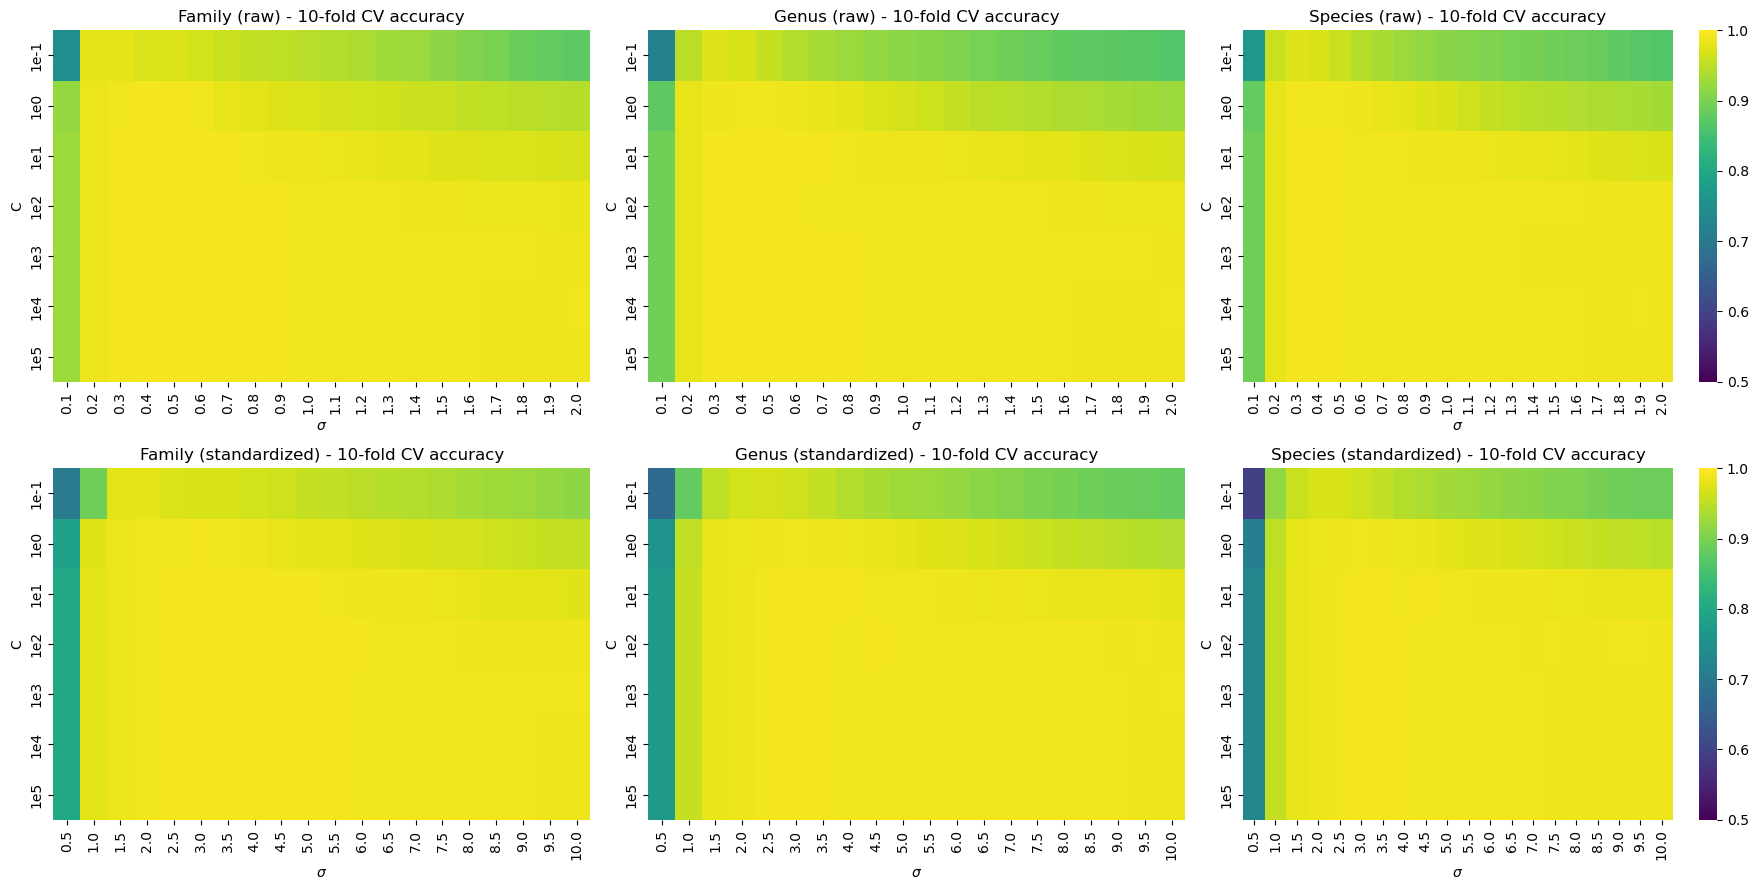

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, version in enumerate(["raw", "standardized"]):
    for ax, lab in zip(axes[r], LABELS):
        res = gauss_cv[version, lab]
        heat = res.pivot(index="C", columns="sigma", values="mean_test_score")
        heat.index = [f"1e{round(np.log10(c))}" for c in heat.index]
        sns.heatmap(heat, cmap="viridis", vmin=0.5, vmax=1, ax=ax, cbar=ax is axes[r, -1])
        ax.set_title(f"{lab} ({version}) - 10-fold CV accuracy")
        ax.set_xlabel("$\\sigma$"); ax.set_ylabel("C")
plt.tight_layout(); plt.show()

In [9]:
pd.concat([record(f"Gaussian SVM ({v})", {lab: gauss[v, lab] for lab in LABELS})
           for v in ["raw", "standardized"]]).round(4)

,acc Family,acc Genus,acc Species,exact match,Hamming loss,Hamming score
Gaussian SVM (raw),0.9949,0.9917,0.9907,0.9893,0.0076,0.9924
Gaussian SVM (standardized),0.9940,0.9880,0.9880,0.9866,0.0100,0.9900


Both versions reach about 99.2% CV accuracy on every label, with $\sigma = 0.4$ (raw) and $\sigma = 3$ to $3.5$ (standardized). CV accuracy is flat once $C \ge 10$ and drops at the smallest widths (0.1 raw, 0.5 standardized), where training accuracy is 100% for $C \ge 1$, i.e. these widths overfit. On the test set the raw attributes are slightly better: Hamming loss 0.0076 vs. 0.0100 (49 vs. 65 wrong labels out of 6477) and exact match 98.9% vs. 98.7%.

#### iii. L1-penalized SVM

I use `LinearSVC(penalty="l1", dual=False)` (one-vs-all) with standardization inside the pipeline, so the scaler is refit in each fold. $C$ is chosen by 10-fold CV over $\log_{10} C \in \{-3, -2.5, \dots, 2\}$. Even the smallest $C$ gives CV accuracy above 70%, and the CV error is flat for $C \ge 1$ (plot in iv). I set `max_iter` high enough that every fit converges, including all CV folds at $C = 100$.

In [10]:
def l1_svm(C=1.0, smote=False):
    steps = [("scale", StandardScaler())]
    if smote:
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("svm", LinearSVC(penalty="l1", dual=False, C=C, max_iter=100000,
                                   random_state=SEED)))
    return ImbPipeline(steps)

C_l1 = np.logspace(-3, 2, 11)

def tune_l1(smote):
    models, curves, rows = {}, {}, []
    for lab in LABELS:
        gs = GridSearchCV(l1_svm(smote=smote), {"svm__C": C_l1}, cv=skf, n_jobs=-1)
        gs.fit(X_train, Y_train[lab])
        models[lab] = gs.best_estimator_
        curves[lab] = gs.cv_results_["mean_test_score"]
        coef = gs.best_estimator_.named_steps["svm"].coef_
        rows.append({"label": lab, "C": gs.best_params_["svm__C"],
                     "CV accuracy": gs.best_score_, "CV error": 1 - gs.best_score_,
                     "nonzero weights": f"{(coef != 0).sum()} / {coef.size}",
                     "features used": int((coef != 0).any(axis=0).sum())})
    return models, curves, pd.DataFrame(rows).set_index("label")

l1, l1_curves, cv_l1 = tune_l1(smote=False)
cv_l1.round(4)

,C,CV accuracy,CV error,nonzero weights,features used
label,,,,,
Family,10.0,0.9412,0.0588,88 / 88,22
Genus,100.0,0.9516,0.0484,176 / 176,22
Species,10.0,0.9607,0.0393,220 / 220,22


In [11]:
record("L1 SVM", l1).round(4)

,acc Family,acc Genus,acc Species,exact match,Hamming loss,Hamming score
L1 SVM,0.9282,0.9416,0.9592,0.9125,0.057,0.943


The L1 SVM is much less accurate than the Gaussian SVM (Hamming loss 0.057 vs. 0.0076, exact match 91.3% vs. 98.9%), and Family is its hardest label (92.8%). Every weight is nonzero at the selected $C$, so the $\ell_1$ penalty does not drop any MFCC.

#### iv. L1-penalized SVM with SMOTE

SMOTE creates synthetic minority samples by interpolating between a minority point and one of its 5 nearest minority neighbours, oversampling every class to the size of the largest one. It sits after the scaler in an `imblearn` pipeline, so only the training part of each fold is oversampled.

In [12]:
l1_smote, l1_smote_curves, cv_l1_smote = tune_l1(smote=True)
cv_l1_smote.round(4)

,C,CV accuracy,CV error,nonzero weights,features used
label,,,,,
Family,3.1623,0.9232,0.0768,86 / 88,22
Genus,1.0000,0.9128,0.0872,175 / 176,22
Species,3.1623,0.9581,0.0419,220 / 220,22


In [13]:
record("L1 SVM + SMOTE", l1_smote).round(4)

,acc Family,acc Genus,acc Species,exact match,Hamming loss,Hamming score
L1 SVM + SMOTE,0.9092,0.9023,0.9579,0.8536,0.0769,0.9231


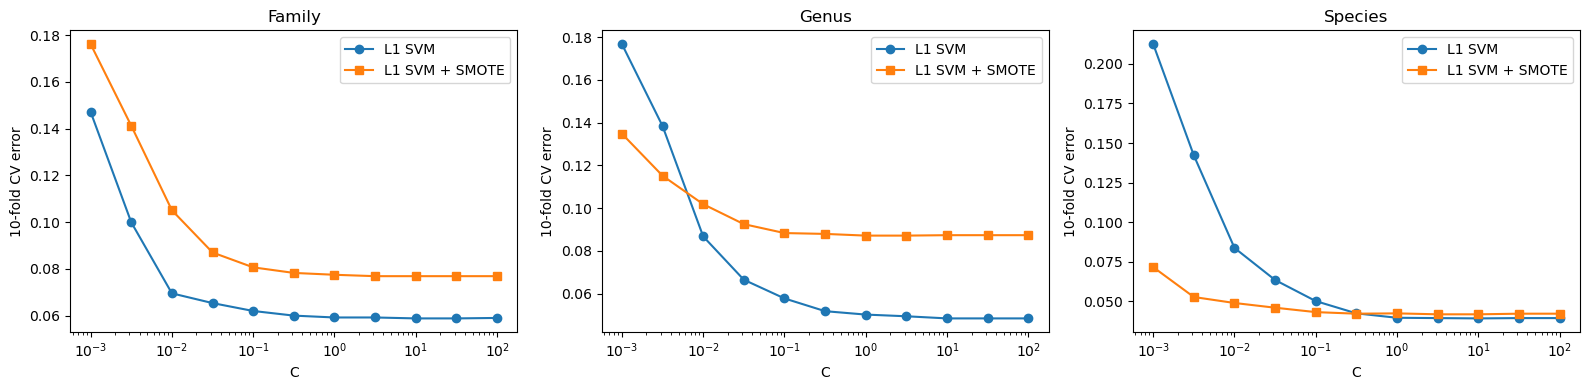

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lab in zip(axes, LABELS):
    ax.semilogx(C_l1, 1 - l1_curves[lab], "o-", label="L1 SVM")
    ax.semilogx(C_l1, 1 - l1_smote_curves[lab], "s-", label="L1 SVM + SMOTE")
    ax.set(title=lab, xlabel="C", ylabel="10-fold CV error")
    ax.legend()
plt.tight_layout(); plt.show()

Accuracy hides the small classes, so I also report balanced accuracy (mean per-class recall) and per-species recall.

In [15]:
comp = pd.DataFrame({(name, metric): [f(Y_test[lab], preds[name][lab]) for lab in LABELS]
                     for name in ["L1 SVM", "L1 SVM + SMOTE"]
                     for metric, f in [("accuracy", accuracy_score),
                                       ("balanced accuracy", balanced_accuracy_score)]},
                    index=LABELS)
comp.round(4)

L1 SVM                   L1 SVM + SMOTE                  
        accuracy balanced accuracy       accuracy balanced accuracy
Family    0.9282            0.6902         0.9092            0.9131
Genus     0.9416            0.7690         0.9023            0.9162
Species   0.9592            0.8948         0.9579            0.9276

In [16]:
species_recall = pd.DataFrame({
    "test count": Y_test["Species"].value_counts().reindex(classes["Species"]),
    **{name: recall_score(Y_test["Species"], preds[name]["Species"], average=None, labels=classes["Species"])
       for name in ["Gaussian SVM (raw)", "L1 SVM", "L1 SVM + SMOTE"]}}, index=classes["Species"])
species_recall.round(3)

,test count,Gaussian SVM (raw),L1 SVM,L1 SVM + SMOTE
AdenomeraAndre,220,0.982,0.914,0.877
AdenomeraHylaedactylus,1031,1.000,0.999,0.995
Ameeregatrivittata,162,1.000,0.944,0.944
HylaMinuta,84,0.964,0.774,0.893
HypsiboasCinerascens,135,0.978,0.963,0.963
HypsiboasCordobae,333,0.997,0.976,0.943
LeptodactylusFuscus,96,0.979,0.896,0.906
OsteocephalusOophagus,34,0.882,0.647,0.882
Rhinellagranulosa,27,0.926,0.889,0.926
ScinaxRuber,37,0.973,0.946,0.946


**Effect of SMOTE.** Overall accuracy drops (Hamming loss 0.057 → 0.077, exact match 91.3% → 85.4%), but minority-class recall improves. Balanced accuracy rises from 0.69 to 0.91 (Family) and from 0.77 to 0.92 (Genus). Without SMOTE, *Bufonidae* is never predicted (0/27, see the confusion matrices in vi); with SMOTE 24/27 are found, and *Rhinella* goes from 7/27 to 25/27. The cost is new false positives taken from the large classes (e.g. 43 *Hylidae*/*Leptodactylidae* syllables predicted as *Bufonidae*), which lowers accuracy. For Species, accuracy barely changes (0.959 → 0.958) while balanced accuracy rises (0.895 → 0.928).

**Conclusions.**
- The Gaussian SVM is the best binary relevance model (Hamming loss 0.0076, exact match 98.9%, recall ≥ 0.88 for every species without resampling). Raw and standardized attributes are close.
- The L1 SVM is clearly worse (Hamming loss 0.057) and has its lowest recall on small classes (e.g. 0/27 for *Bufonidae*, 7/27 for *Rhinella*).
- SMOTE trades overall accuracy for minority-class recall: useful if the rare classes matter, otherwise the plain L1 SVM is better.
- The split ignores `RecordID`, so syllables from the same recording are in both training and test, and the test scores may be optimistic.

#### v. Extra practice: classifier chain

Binary relevance ignores that the labels are related (species determines genus, genus determines family). A classifier chain adds the earlier labels as inputs to the later classifiers:

$$h_1: x \to \text{Family}, \qquad h_2: (x, \text{Family}) \to \text{Genus}, \qquad h_3: (x, \text{Family}, \text{Genus}) \to \text{Species}.$$

Earlier labels are one-hot encoded: true labels in training, predicted labels at test time. I reuse the raw-attribute Gaussian SVM and its $(C, \sigma)$ from ii without re-tuning.

In [17]:
def one_hot(values, lab):
    return (np.asarray(values)[:, None] == classes[lab]).astype(float)

class Chain:
    def __init__(self, order, params):
        self.order, self.params = order, params

    def fit(self, X, Y):
        Z, self.models = np.asarray(X), {}
        for lab in self.order:
            C, sigma = self.params[lab]
            self.models[lab] = OneVsRestClassifier(SVC(C=C, gamma=1 / (2 * sigma ** 2))).fit(Z, Y[lab])
            Z = np.hstack([Z, one_hot(Y[lab], lab)])
        return self

    def _run(self, X):
        Z, P, S = np.asarray(X), {}, {}
        for lab in self.order:
            P[lab] = self.models[lab].predict(Z)
            S[lab] = self.models[lab].decision_function(Z)
            Z = np.hstack([Z, one_hot(P[lab], lab)])
        return P, S

class ChainLink:
    # lets a single link of the chain be used like the other models in record()
    def __init__(self, chain, lab):
        self.chain, self.lab = chain, lab
    def predict(self, X):
        return self.chain._run(X)[0][self.lab]
    def decision_function(self, X):
        return self.chain._run(X)[1][self.lab]

params = {lab: tuple(cv_gauss.loc[("raw", lab), ["C", "sigma"]]) for lab in LABELS}
chain = Chain(["Family", "Genus", "Species"], params).fit(X_train, Y_train)
record("Classifier chain", {lab: ChainLink(chain, lab) for lab in LABELS}).round(4)

,acc Family,acc Genus,acc Species,exact match,Hamming loss,Hamming score
Classifier chain,0.9949,0.9907,0.9898,0.9898,0.0082,0.9918


In [18]:
consistent = Y.drop_duplicates()
for name in ["Gaussian SVM (raw)", "Classifier chain"]:
    ok = preds[name].merge(consistent, how="left", indicator=True)["_merge"].eq("both").mean()
    print(f"{name}: {ok:.4f} of the predicted triplets are valid (family, genus, species) combinations")

Gaussian SVM (raw): 0.9949 of the predicted triplets are valid (family, genus, species) combinations
Classifier chain: 0.9977 of the predicted triplets are valid (family, genus, species) combinations


The chain is about as good as binary relevance (Hamming loss 0.0082 vs. 0.0076, exact match 0.9898 vs. 0.9893). Family is identical (same first model), and genus and species are slightly lower. Its errors fall on fewer syllables, and more of its predicted triplets are valid combinations (99.77% vs. 99.49%). Overall the difference is only a few test syllables.

#### vi. Extra practice: confusion matrices, precision, recall, ROC and AUC

- **Confusion matrix:** multi-label classification has one $2 \times 2$ matrix (TP, FP, FN, TN) per binary label. Each label group here is multi-class, so I show one $k \times k$ matrix per group; a class's $2 \times 2$ matrix is its one-vs-rest view.
- **Precision / recall:** per class, $TP/(TP+FP)$ and $TP/(TP+FN)$, then *macro* (mean over classes) or *micro* (pooled counts) averaged. Within a multi-class group micro precision = micro recall = accuracy, so I report macro. Over the 22 binary labels, micro precision and recall, and the example-based versions $|Y_i \cap \hat Y_i| / |\hat Y_i|$ and $|Y_i \cap \hat Y_i| / |Y_i|$, all equal the Hamming score, since every syllable has exactly 3 true and 3 predicted labels.
- **ROC / AUC:** one-vs-rest ROC curve per class from the SVM decision values; macro AUC averages the per-class AUCs, and micro AUC pools all (instance, class) pairs.

The "all 22" rows treat the problem as 22 binary labels (4 families + 8 genera + 10 species).

In [19]:
rows = []
for name in preds:
    Yb_all, Pb_all, S_all = [], [], []
    for lab in LABELS:
        y, p, s = Y_test[lab], preds[name][lab], dec[name][lab]
        yb = label_binarize(y, classes=classes[lab])
        Yb_all.append(yb); Pb_all.append(label_binarize(p, classes=classes[lab])); S_all.append(s)
        prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
        rows.append({"model": name, "label": lab, "macro precision": prec, "macro recall": rec,
                     "macro F1": f1, "macro AUC": roc_auc_score(yb, s, average="macro"),
                     "micro AUC": roc_auc_score(yb, s, average="micro")})
    Yb_all, Pb_all, S_all = np.hstack(Yb_all), np.hstack(Pb_all), np.hstack(S_all)
    prec, rec, f1, _ = precision_recall_fscore_support(Yb_all, Pb_all, average="macro", zero_division=0)
    rows.append({"model": name, "label": "all 22", "macro precision": prec, "macro recall": rec,
                 "macro F1": f1, "macro AUC": roc_auc_score(Yb_all, S_all, average="macro"),
                 "micro AUC": roc_auc_score(Yb_all, S_all, average="micro")})

metrics_vi = pd.DataFrame(rows).set_index(["model", "label"])
metrics_vi.round(4)

macro precision  macro recall  macro F1  \
model                       label                                              
Gaussian SVM (raw)          Family            0.9947        0.9782    0.9861   
                            Genus             0.9874        0.9615    0.9740   
                            Species           0.9807        0.9681    0.9742   
                            all 22            0.9857        0.9676    0.9763   
Gaussian SVM (standardized) Family            0.9943        0.9788    0.9862   
                            Genus             0.9826        0.9497    0.9653   
                            Species           0.9765        0.9573    0.9665   
                            all 22            0.9820        0.9585    0.9696   
L1 SVM                      Family            0.6756        0.6902    0.6828   
                            Genus             0.9237        0.7690    0.8091   
                            Species           0.9254        0.8948    0.9060   
                            all 22            0.8794        0.8119    0.8302   
L1 SVM + SMOTE              Family            0.7421        0.9131    0.7947   
                            Genus             0.7415        0.9162    0.8024   
                            Species           0.8857        0.9276    0.9035   
                            all 22            0.8072        0.9208    0.8469   
Classifier chain            Family            0.9947        0.9782    0.9861   
                            Genus             0.9847        0.9607    0.9723   
                            Species           0.9821        0.9649    0.9732   
                            all 22            0.9854        0.9658    0.9752   

                                     macro AUC  micro AUC  
model                       label                          
Gaussian SVM (raw)          Family      0.9996     0.9997  
                            Genus       0.9973     0.9994  
                            Species     0.9973     0.9990  
                            all 22      0.9977     0.9993  
Gaussian SVM (standardized) Family      0.9986     0.9996  
                            Genus       0.9967     0.9992  
                            Species     0.9969     0.9989  
                            all 22      0.9971     0.9992  
L1 SVM                      Family      0.9768     0.9846  
                            Genus       0.9856     0.9925  
                            Species     0.9888     0.9944  
                            all 22      0.9855     0.9922  
L1 SVM + SMOTE              Family      0.9678     0.9763  
                            Genus       0.9769     0.9832  
                            Species     0.9839     0.9921  
                            all 22      0.9784     0.9866  
Classifier chain            Family      0.9996     0.9997  
                            Genus       0.9989     0.9987  
                            Species     0.9981     0.9986  
                            all 22      0.9986     0.9989

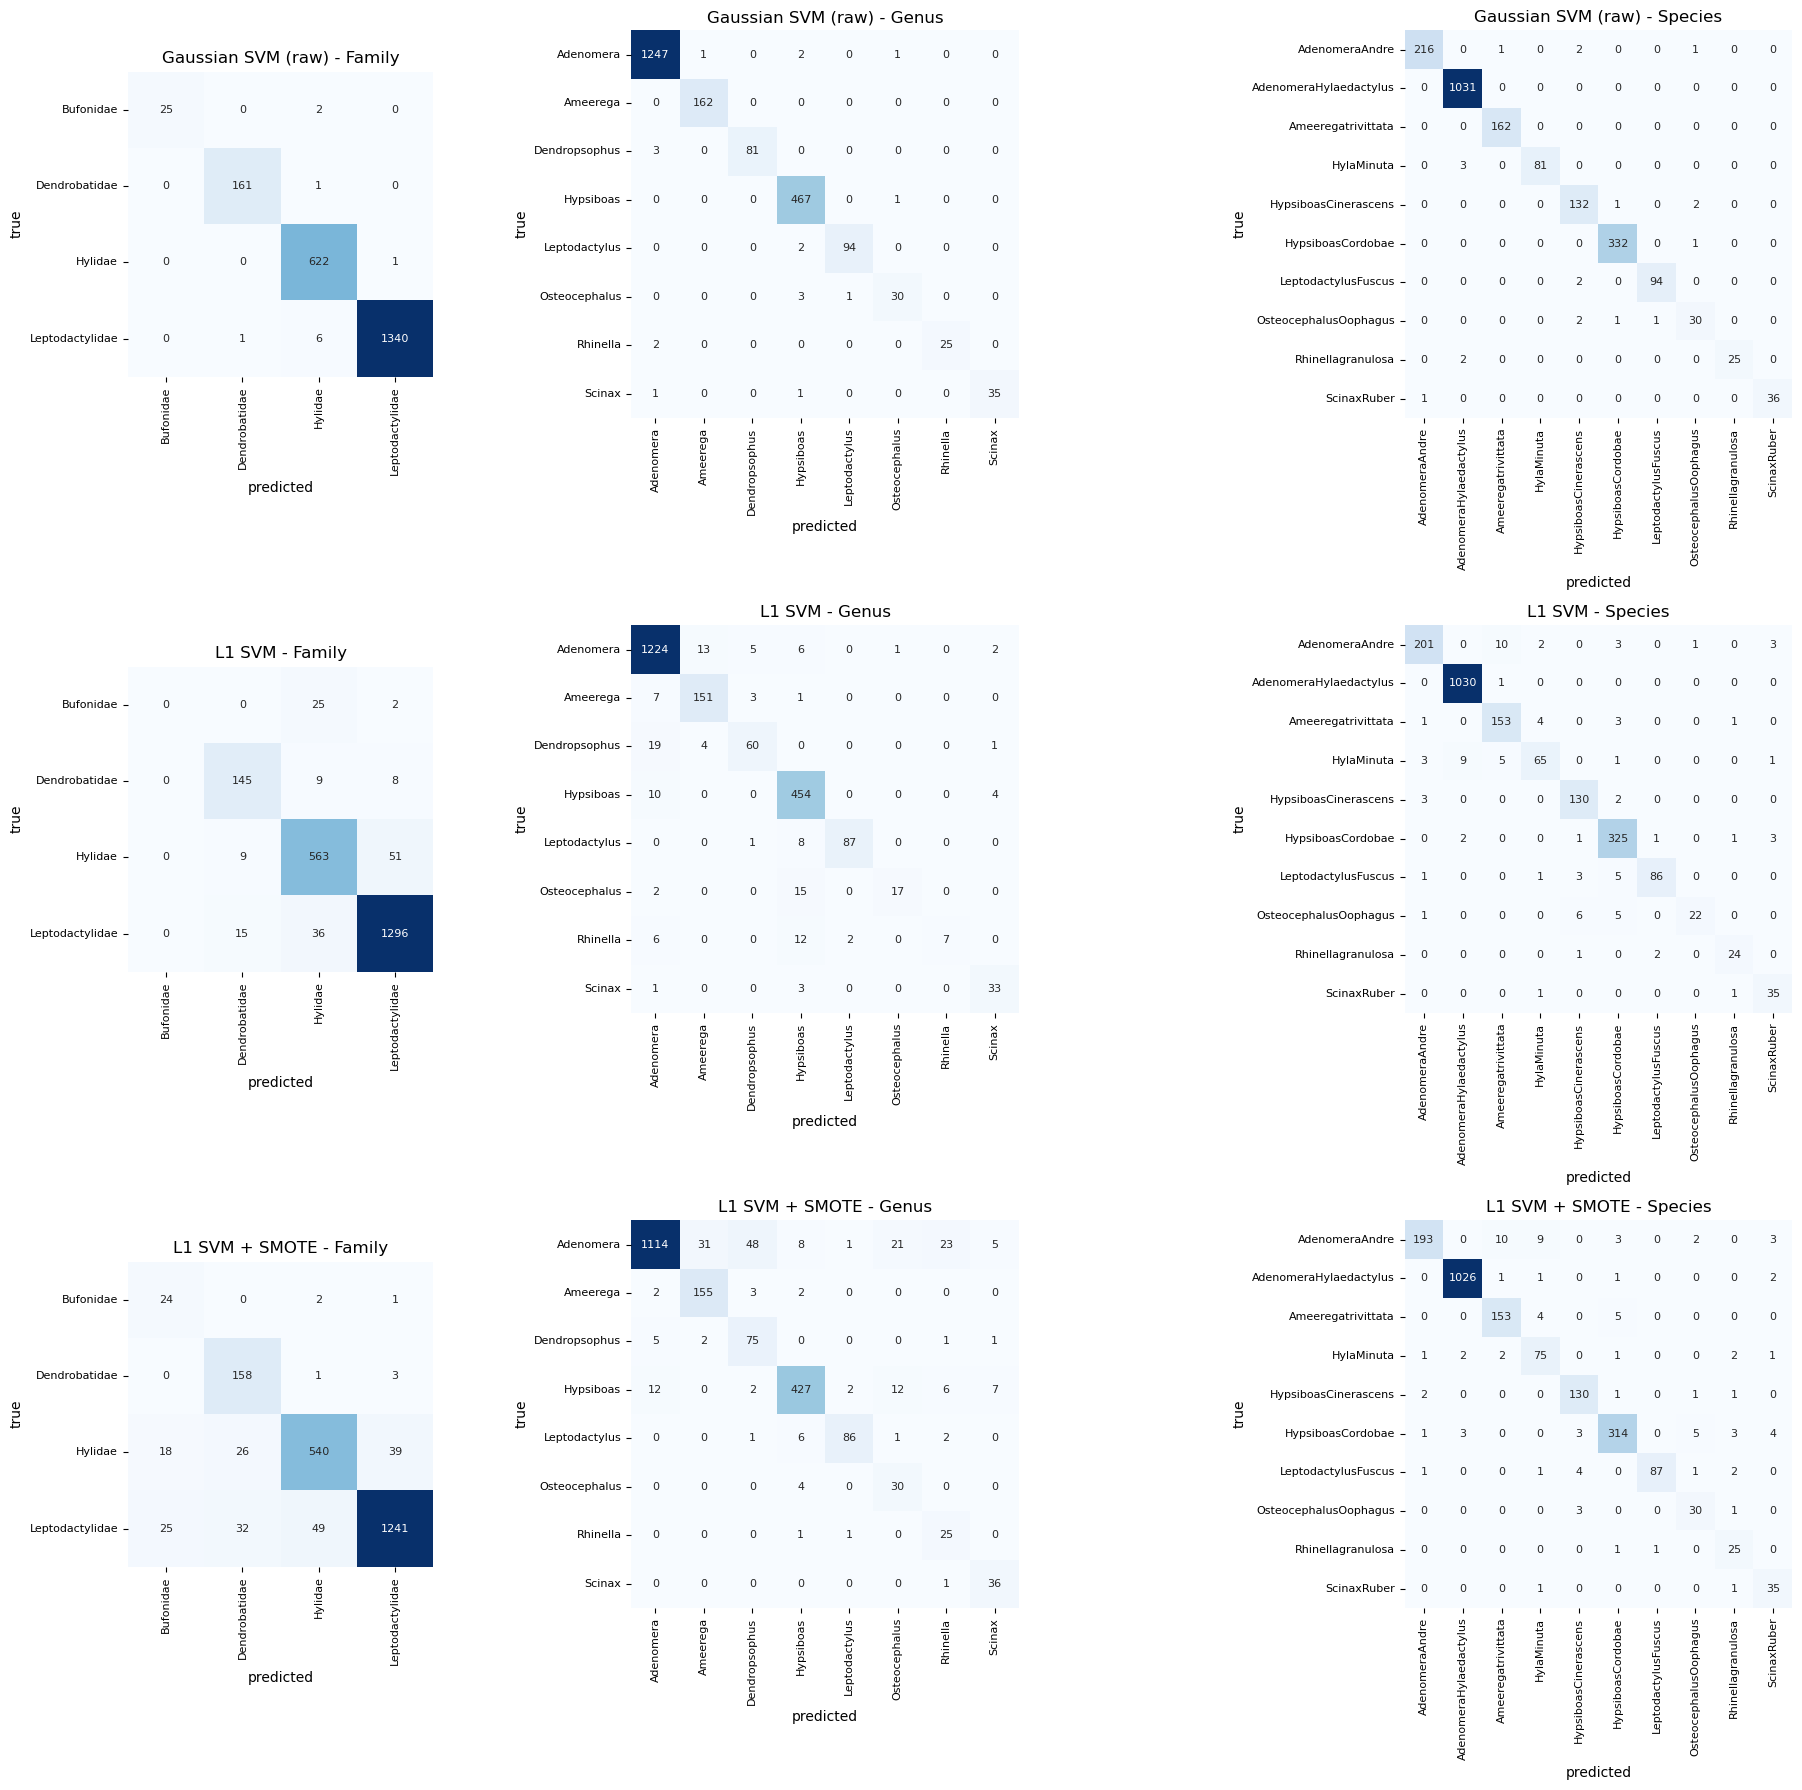

In [20]:
cm_models = ["Gaussian SVM (raw)", "L1 SVM", "L1 SVM + SMOTE"]
fig, axes = plt.subplots(len(cm_models), 3, figsize=(20, 6 * len(cm_models)),
                         gridspec_kw={"width_ratios": [4, 8, 10]})
for r, name in enumerate(cm_models):
    for ax, lab in zip(axes[r], LABELS):
        cm = confusion_matrix(Y_test[lab], preds[name][lab], labels=classes[lab])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, square=True,
                    xticklabels=classes[lab], yticklabels=classes[lab], annot_kws={"size": 8})
        ax.set(title=f"{name} - {lab}", xlabel="predicted", ylabel="true")
        ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

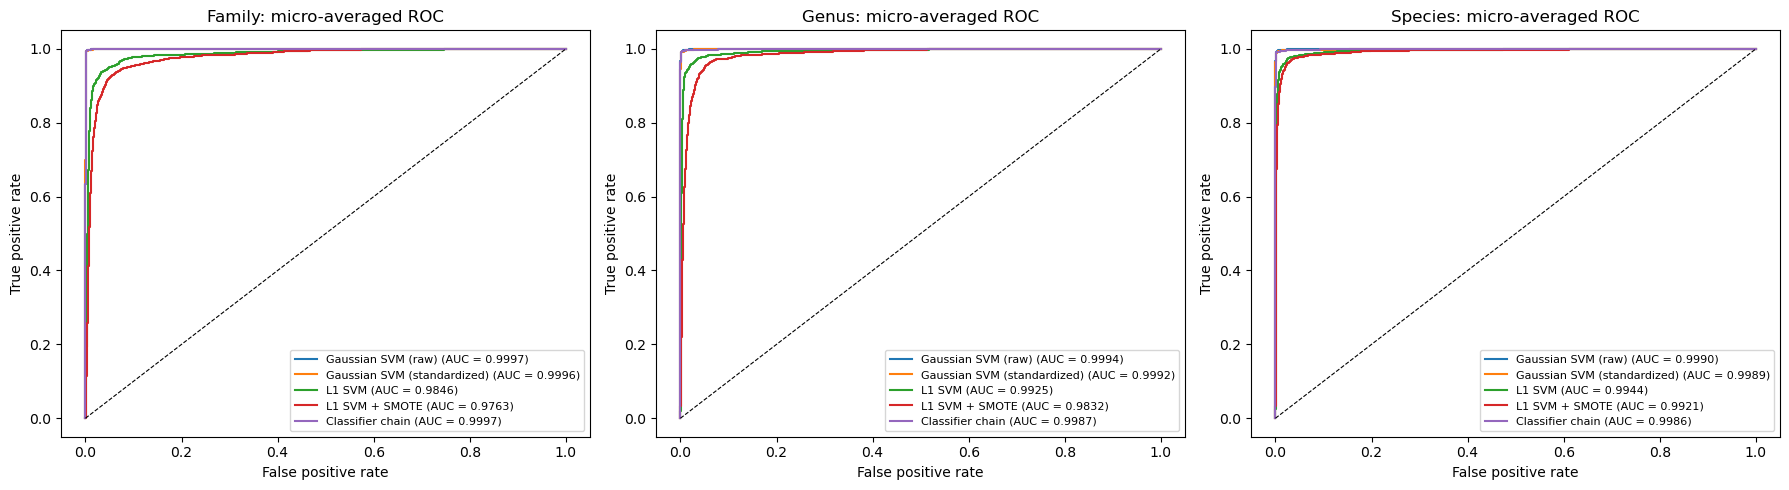

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, LABELS):
    yb = label_binarize(Y_test[lab], classes=classes[lab])
    for name in preds:
        fpr, tpr, _ = roc_curve(yb.ravel(), dec[name][lab].ravel())
        ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yb, dec[name][lab], average='micro'):.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set(title=f"{lab}: micro-averaged ROC", xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

The Gaussian SVMs and the chain have macro precision and recall of about 0.95 to 0.99 and micro AUC near 0.999. The L1 SVM's macro recall is much lower than its precision for Genus (0.77 vs. 0.92), and both are below 0.7 for Family because *Bufonidae* is never predicted. SMOTE raises macro recall to 0.91 to 0.93 and lowers macro precision for Genus and Species. All AUCs are at least 0.96, even with low macro recall, because AUC only measures how the scores rank the instances, not the argmax decision.

#### Summary of all classifiers (test set)

In [22]:
summary = pd.DataFrame(scores).T
summary.round(4)

,acc Family,acc Genus,acc Species,exact match,Hamming loss,Hamming score
Gaussian SVM (raw),0.9949,0.9917,0.9907,0.9893,0.0076,0.9924
Gaussian SVM (standardized),0.9940,0.9880,0.9880,0.9866,0.0100,0.9900
L1 SVM,0.9282,0.9416,0.9592,0.9125,0.0570,0.9430
L1 SVM + SMOTE,0.9092,0.9023,0.9579,0.8536,0.0769,0.9231
Classifier chain,0.9949,0.9907,0.9898,0.9898,0.0082,0.9918


By Hamming loss: Gaussian SVM (raw) < classifier chain < Gaussian SVM (standardized) < L1 SVM < L1 SVM + SMOTE. Exact match gives the same order, except that the chain is slightly ahead of the raw Gaussian SVM.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) K-means on the whole data set, choosing $k$ automatically

I choose the $k$ with the largest average silhouette $s(i) = (b(i) - a(i)) / \max\{a(i), b(i)\}$, where $a(i)$ is the mean distance from point $i$ to the other points in its cluster and $b(i)$ to the nearest other cluster. The silhouette is undefined for $k = 1$, so I search $k \in \{2, \dots, 50\}$ and report $k = 1$ as a baseline in (c). Each of the 50 Monte Carlo runs uses a different seed (10 k-means++ starts per $k$) and repeats (a) to (c).

In [23]:
X_all = X.to_numpy()
K = np.arange(2, 51)

def kmeans_run(seed):
    sil, fits = [], {}
    for k in K:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_all)
        fits[k] = km.labels_
        sil.append(silhouette_score(X_all, km.labels_))
    k_best = K[int(np.argmax(sil))]
    return k_best, np.array(sil), fits[k_best]

runs = Parallel(n_jobs=-1)(delayed(kmeans_run)(seed) for seed in range(50))
chosen_k = pd.Series([r[0] for r in runs])
chosen_k.value_counts().rename_axis("k").to_frame("runs")

,runs
k,
4,50


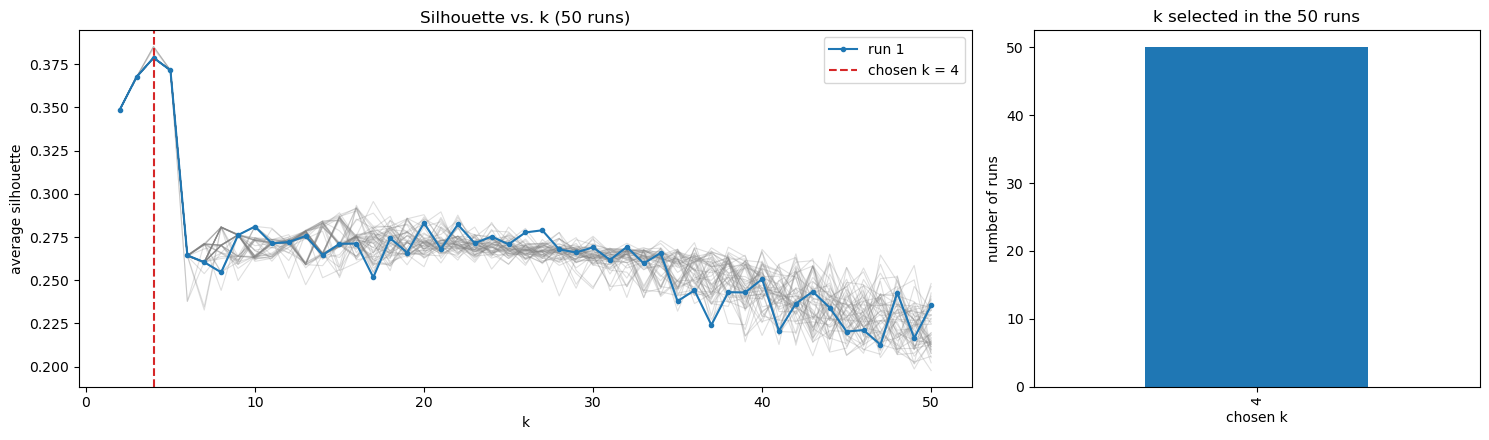

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for k_best, sil, _ in runs:
    axes[0].plot(K, sil, color="gray", alpha=0.25, lw=0.8)
axes[0].plot(K, runs[0][1], "o-", ms=3, color="tab:blue", label="run 1")
axes[0].axvline(runs[0][0], color="tab:red", ls="--", label=f"chosen k = {runs[0][0]}")
axes[0].set(xlabel="k", ylabel="average silhouette", title="Silhouette vs. k (50 runs)")
axes[0].legend()
chosen_k.value_counts().sort_index().plot.bar(ax=axes[1], color="tab:blue")
axes[1].set(xlabel="chosen k", ylabel="number of runs", title="k selected in the 50 runs")
plt.tight_layout(); plt.show()

All 50 runs choose $k = 4$, where the silhouette peaks (about 0.38); it drops sharply after $k = 5$.

### (b) Majority family, genus and species in each cluster

Each label's majority is taken separately within each cluster (first run shown).

In [25]:
def majority_triplets(cluster, Y):
    return Y.groupby(cluster).agg(lambda s: s.value_counts().idxmax())

k1, _, cl1 = runs[0]
maj1 = majority_triplets(cl1, Y)
maj1.insert(0, "size", np.bincount(cl1))
for lab in LABELS:
    maj1[f"{lab} share"] = [(Y[lab][cl1 == c] == maj1.loc[c, lab]).mean() for c in maj1.index]
maj1.rename_axis("cluster").round(3)

,size,Family,Genus,Species,Family share,Genus share,Species share
cluster,,,,,,,
0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,0.972,0.971,0.971
1,1982,Hylidae,Hypsiboas,HypsiboasCordobae,0.628,0.524,0.514
2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata,0.485,0.485,0.485
3,614,Hylidae,Hypsiboas,HypsiboasCinerascens,0.961,0.883,0.736


Cluster 0 is almost pure (97% *Leptodactylidae / Adenomera / AdenomeraHylaedactylus*); cluster 3 is 96% *Hylidae* but only 74% *HypsiboasCinerascens*. Clusters 1 and 2 are mixed, and in cluster 2 the majority labels cover less than half of the syllables. Only 4 of the 10 species are a cluster majority, so the other 6 always get the wrong species label.

### (c) Hamming distance, Hamming score and Hamming loss

Each syllable gets its cluster's majority triplet. With $d_i$ from 1(b)i: average Hamming distance $= \frac{1}{n}\sum_i d_i$, Hamming loss $= \frac{1}{3n}\sum_i d_i$, Hamming score $= 1 - \text{Hamming loss}$.

In [26]:
def hamming_summary(cluster, Y):
    maj = majority_triplets(cluster, Y)
    d = (maj.loc[cluster].to_numpy() != Y.to_numpy()).sum(axis=1)
    return {"k": len(maj), "Hamming distance": d.mean(), "Hamming loss": d.mean() / 3,
            "Hamming score": 1 - d.mean() / 3, "exact match": (d == 0).mean()}

mc = pd.DataFrame([hamming_summary(cl, Y) for _, _, cl in runs])
mc.round(4).value_counts().rename("number of runs").to_frame()

number of runs
k Hamming distance Hamming loss Hamming score exact match                
4 0.6673           0.2224       0.7776        0.7555                   35
  0.6674           0.2225       0.7775        0.7554                    4
  0.6653           0.2218       0.7782        0.7564                    2
  0.6657           0.2219       0.7781        0.7562                    2
  0.6669           0.2223       0.7777        0.7557                    2
  0.7358           0.2453       0.7547        0.6828                    2
  0.6664           0.2221       0.7779        0.7558                    1
  0.7012           0.2337       0.7663        0.7274                    1
  0.7354           0.2451       0.7549        0.6830                    1

In [27]:
mc.agg(["mean", "std"]).round(4)

,k,Hamming distance,Hamming loss,Hamming score,exact match
mean,4.0,0.6719,0.2240,0.7760,0.7507
std,0.0,0.0170,0.0057,0.0057,0.0178


In [28]:
baseline = hamming_summary(np.zeros(len(Y), dtype=int), Y)
print("k = 1 (whole data set as one cluster):", {k: round(v, 4) for k, v in baseline.items()})

k = 1 (whole data set as one cluster): {'k': 1, 'Hamming distance': 1.3255, 'Hamming loss': 0.4418, 'Hamming score': 0.5582, 'exact match': 0.4834}


Over the 50 runs, the average Hamming distance is 0.672 (std 0.017), the Hamming loss 0.224 (std 0.006) and the Hamming score 0.776 (std 0.006); about 75% of the syllables get all three labels right. 46 runs have an average Hamming distance between 0.665 and 0.668 (35 give exactly the same result), and most of the std comes from 4 runs that reach a worse solution (0.70 to 0.74). K-means halves the loss of a single cluster (0.442) but is far from the supervised SVMs (below 0.01); with 4 clusters, at most 4 of the 10 species can be predicted.

## 3. ISLR 12.6.2

Dissimilarity matrix of the four observations:

$$\begin{bmatrix} & 0.3 & 0.4 & 0.7 \\ 0.3 & & 0.5 & 0.8 \\ 0.4 & 0.5 & & 0.45 \\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

**(a) Complete linkage.** The smallest dissimilarity is $d(1,2) = 0.3$, so 1 and 2 fuse at 0.3. Then
$d(\{1,2\}, 3) = \max(0.4, 0.5) = 0.5$, $d(\{1,2\}, 4) = \max(0.7, 0.8) = 0.8$ and $d(3, 4) = 0.45$, so 3 and 4 fuse at 0.45.
Finally $d(\{1,2\}, \{3,4\}) = \max(0.4, 0.5, 0.7, 0.8) = 0.8$.

**(b) Single linkage.** 1 and 2 again fuse first at 0.3. Then
$d(\{1,2\}, 3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\}, 4) = \min(0.7, 0.8) = 0.7$ and $d(3, 4) = 0.45$, so 3 joins $\{1,2\}$ at 0.4.
Finally $d(\{1,2,3\}, 4) = \min(0.7, 0.8, 0.45) = 0.45$.

The fusion heights are labeled in the dendrograms below.

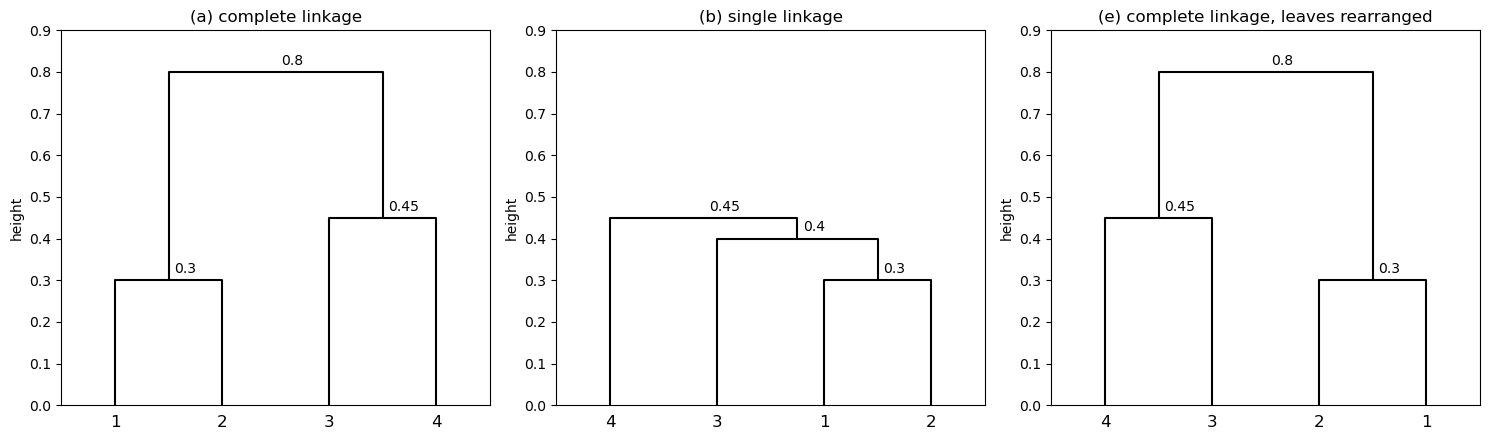

In [29]:
D = np.array([[0.0, 0.3, 0.4, 0.7],
              [0.3, 0.0, 0.5, 0.8],
              [0.4, 0.5, 0.0, 0.45],
              [0.7, 0.8, 0.45, 0.0]])
Z_complete = linkage(squareform(D), method="complete")
Z_single = linkage(squareform(D), method="single")

# (e): swap the two branches at every fusion of the complete-linkage tree
Z_swapped = Z_complete.copy()
Z_swapped[:, [0, 1]] = Z_swapped[:, [1, 0]]

def plot_dendrogram(Z, ax, title):
    dn = dendrogram(Z, labels=[1, 2, 3, 4], ax=ax, color_threshold=0, above_threshold_color="k")
    for xs, ys in zip(dn["icoord"], dn["dcoord"]):
        ax.annotate(f"{ys[1]:g}", (np.mean(xs[1:3]), ys[1]), xytext=(4, 3),
                    textcoords="offset points", ha="left", va="bottom")
    ax.set(title=title, ylabel="height", ylim=(0, 0.9))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_dendrogram(Z_complete, axes[0], "(a) complete linkage")
plot_dendrogram(Z_single, axes[1], "(b) single linkage")
plot_dendrogram(Z_swapped, axes[2], "(e) complete linkage, leaves rearranged")
plt.tight_layout(); plt.show()

**(c)** Cutting the complete-linkage tree into two clusters (any height between 0.45 and 0.8) gives $\{1, 2\}$ and $\{3, 4\}$.

**(d)** Cutting the single-linkage tree into two clusters (any height between 0.4 and 0.45) gives $\{1, 2, 3\}$ and $\{4\}$.

**(e)** Swapping the branches at a fusion only changes the leaf order. The right plot (leaves 4, 3, 2, 1) has the same fusions as (a), so it has the same meaning.